In [1]:
import pandas as pd

In [2]:
df=pd.read_csv(r"C:\Users\User\Desktop\Areeba-Data\datasets\retail_sales_dataset.csv")

In [3]:
df

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB


In [5]:
#start cleaning
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [8]:
#city wise sales
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

In [9]:
#correct datatype
df["Date"]=pd.to_datetime(df["Date"])

In [10]:
df.dtypes

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [13]:
#total amount ka sum
print(df["Total Amount"].sum())

456000


In [14]:
print(df["Quantity"].sum())
#total products sold

2514


In [15]:
#unique customers
df["Customer ID"].nunique()


1000

In [17]:
df["Customer ID"].value_counts().sum()

np.int64(1000)

In [19]:
#category wise sales
df.groupby("Product Category")["Total Amount"].sum()

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

In [20]:
#gender wise sales
df.groupby("Gender")["Total Amount"].sum()

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

In [24]:
#monthly sales
df["Month"]=df["Date"].dt.to_period("M")

In [26]:
df.groupby("Month")["Total Amount"].sum()

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [27]:
df["Age Group"]=pd.cut(df["Age"],bins=[0,18,30,45,60,100],
                       labels=["Under 18","18-30","31-45","46-60","60+"]
                      )

In [28]:
#age wise sales
df.groupby("Age Group")["Total Amount"].sum()

Age Group
Under 18     11215
18-30       121730
31-45       141955
46-60       147875
60+          33225
Name: Total Amount, dtype: int64

In [29]:
# 5 top transactions
df.nlargest(5,"Total Amount")

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Age Group
14,15,2023-01-16,CUST015,Female,42,Electronics,4,500,2000,2023-01,31-45
64,65,2023-12-05,CUST065,Male,51,Electronics,4,500,2000,2023-12,46-60
71,72,2023-05-23,CUST072,Female,20,Electronics,4,500,2000,2023-05,18-30
73,74,2023-11-22,CUST074,Female,18,Beauty,4,500,2000,2023-11,Under 18
88,89,2023-10-01,CUST089,Female,55,Electronics,4,500,2000,2023-10,46-60


In [38]:
#step-1
#KPIs 
#-1 Total revenue
total_revenue=df["Total Amount"].sum()
#-2 Total unit sold
total_quantity=df["Quantity"].sum()
#-3 unique customers
total_customers=df["Customer ID"].nunique()
#-4 average transaction values
average_transactions=df["Transaction ID"].mean()
#-5 total transactions
total_transaction=df["Transaction ID"].nunique()

print("Total Revenue:",total_revenue)
print("Total Units sold:",total_quantity)
print("Unique Customers:",total_customers)
print("Average Transaction Values:",round(average_transactions,2))
print("Total Transactions:",total_transaction)

Total Revenue: 456000
Total Units sold: 2514
Unique Customers: 1000
Average Transaction Values: 500.5
Total Transactions: 1000


In [39]:
import matplotlib.pyplot as plt

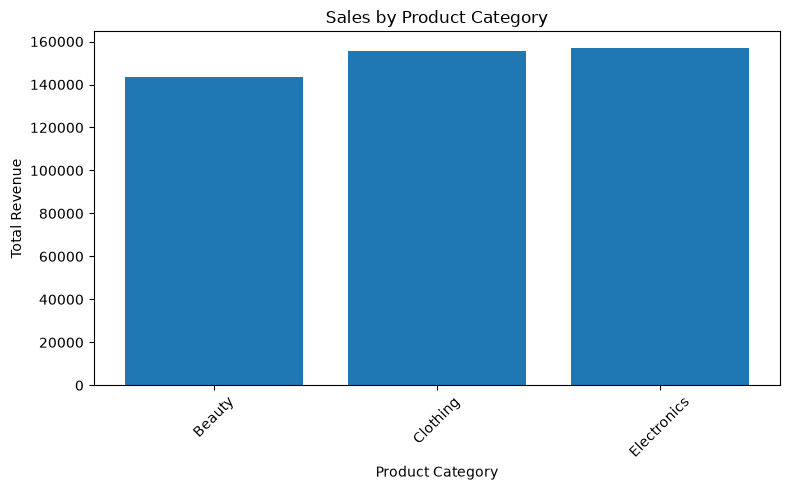

In [41]:
#gargh category wise sales
category_sales=df.groupby("Product Category")["Total Amount"].sum()
plt.figure(figsize=(8,5))
plt.bar(category_sales.index,category_sales.values)
plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

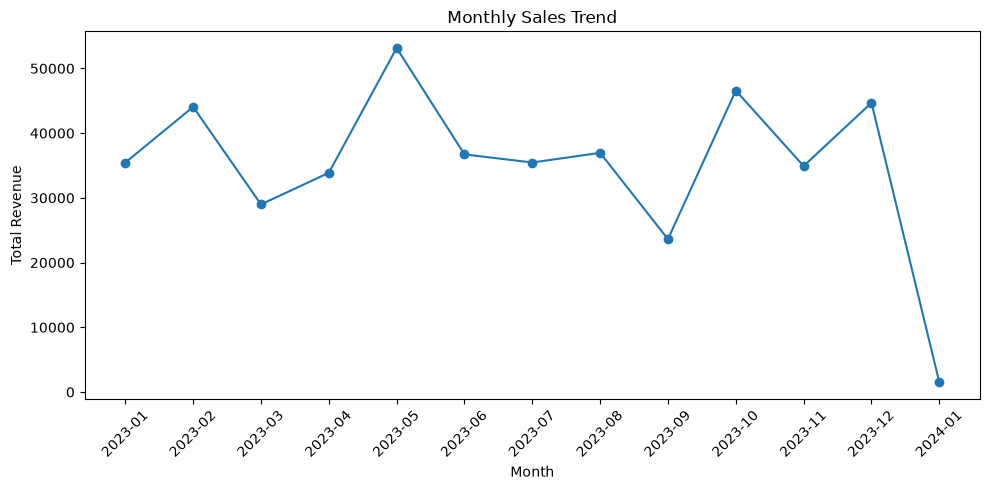

In [42]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()